In [1]:
!pip install -q google-api-python-client transformers emoji wordcloud
print("Installed")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 610.9/610.9 kB 11.2 MB/s eta 0:00:00
Installed


In [2]:
from googleapiclient.discovery import build
from googleapiclient.errors import HttpError
import pandas as pd, re

API_KEY = "YAHAN_APNI_KEY_PASTE_KARO"
BRAND = "Khaadi"
yt = build("youtube", "v3", developerKey=API_KEY)

def search_videos(q, pages=2):
    ids, token = [], None
    for _ in range(pages):
        try:
            params = dict(q=q, part="id", type="video", regionCode="PK", maxResults=50)
            if token:
                params["pageToken"] = token
            r = yt.search().list(**params).execute()
        except HttpError as e:
            print("Search error:", str(e)[:300])
            break
        for i in r.get("items", []):
            vid = i.get("id", {}).get("videoId")
            if vid:
                ids.append(vid)
        token = r.get("nextPageToken")
        if not token:
            break
    return ids

queries = [BRAND, f"{BRAND} Pakistan", f"{BRAND} ad", f"{BRAND} review",
           f"{BRAND} collection", f"{BRAND} sale", f"{BRAND} lawn", f"{BRAND} haul"]
video_ids = list({v for q in queries for v in search_videos(q)})
print("Videos mile:", len(video_ids))

def dur_sec(d):
    m = re.match(r'PT(?:(\d+)H)?(?:(\d+)M)?(?:(\d+)S)?', d)
    h, mi, s = [int(x or 0) for x in m.groups()]
    return h*3600 + mi*60 + s

rows = []
for i in range(0, len(video_ids), 50):
    r = yt.videos().list(part="snippet,statistics,contentDetails",
                         id=",".join(video_ids[i:i+50])).execute()
    for v in r.get("items", []):
        s, st = v["snippet"], v.get("statistics", {})
        rows.append({"video_id": v["id"], "title": s["title"],
            "channel": s["channelTitle"], "description": s.get("description", ""),
            "video_time": s["publishedAt"],
            "duration": dur_sec(v["contentDetails"]["duration"]),
            "views": int(st.get("viewCount", 0)),
            "likes": int(st.get("likeCount", 0)),
            "n_comments": int(st.get("commentCount", 0))})
videos = pd.DataFrame(rows)

mask = videos.title.str.contains(BRAND, case=False) | videos.channel.str.contains(BRAND, case=False)
videos = videos[mask].sort_values("n_comments", ascending=False).head(60).reset_index(drop=True)
print("Brand videos:", len(videos))

def get_comments(vid, max_c=200):
    out, token = [], None
    while len(out) < max_c:
        try:
            params = dict(part="snippet", videoId=vid, maxResults=100, textFormat="plainText")
            if token:
                params["pageToken"] = token
            r = yt.commentThreads().list(**params).execute()
        except HttpError:
            break
        for it in r.get("items", []):
            s = it["snippet"]["topLevelComment"]["snippet"]
            out.append({"video_id": vid, "comment": s["textDisplay"],
                        "comment_likes": s["likeCount"],
                        "replies": it["snippet"]["totalReplyCount"],
                        "comment_time": s["publishedAt"]})
        token = r.get("nextPageToken")
        if not token:
            break
    return out

all_c = []
for vid in videos.video_id:
    all_c += get_comments(vid)
comments = pd.DataFrame(all_c)
df = comments.merge(videos, on="video_id")
print("Total comments:", len(df))
print(df.drop_duplicates("video_id").channel.value_counts().head(5))
df.to_csv("raw_data.csv", index=False)
df.head()

Videos mile: 439
Brand videos: 60
Total comments: 2022
channel
madawa tv              10
Misbah beauty tips      8
Khaadi                  6
Offers inside           4
hsk vlogs               4
Name: count, dtype: int64


,video_id,comment,comment_likes,replies,comment_time,title,channel,description,video_time,duration,views,likes,n_comments
0,28lYJjJ4Cp4,2026?,0,0,2026-08-23T09:14:52Z,Khaadi X Esra | My Symphony,Khaadi,Embark on a melodious journey of KHAADI X ESRA...,2020-12-11T09:48:09Z,45,649821,11778,1035
1,28lYJjJ4Cp4,ESRA and that MUSIC 📈♥️\nAnbody in August 2026 🔥,0,0,2026-08-04T12:19:58Z,Khaadi X Esra | My Symphony,Khaadi,Embark on a melodious journey of KHAADI X ESRA...,2020-12-11T09:48:09Z,45,649821,11778,1035
2,28lYJjJ4Cp4,damn love the music,0,0,2026-06-20T16:37:45Z,Khaadi X Esra | My Symphony,Khaadi,Embark on a melodious journey of KHAADI X ESRA...,2020-12-11T09:48:09Z,45,649821,11778,1035
3,28lYJjJ4Cp4,Nostalgia. Nostalgic muics,0,0,2026-06-15T17:48:06Z,Khaadi X Esra | My Symphony,Khaadi,Embark on a melodious journey of KHAADI X ESRA...,2020-12-11T09:48:09Z,45,649821,11778,1035
4,28lYJjJ4Cp4,Anyone know Music name ?,0,0,2026-05-24T08:34:24Z,Khaadi X Esra | My Symphony,Khaadi,Embark on a melodious journey of KHAADI X ESRA...,2020-12-11T09:48:09Z,45,649821,11778,1035


In [3]:
import emoji

NORMALIZE = {"accha":"acha","achaa":"acha","bht":"bohat","boht":"bohat","bohot":"bohat",
             "mahnga":"mehnga","mehngi":"mehnga","bekaar":"bekar","zabrdast":"zabardast",
             "khubsurat":"khoobsurat","khobsurat":"khoobsurat"}

def clean(t):
    t = str(t).lower()
    t = re.sub(r"http\S+|www\S+", "", t)
    t = emoji.demojize(t, delimiters=(" ", " "))
    t = re.sub(r"[^\w\s\u0600-\u06FF]", " ", t)
    return " ".join(NORMALIZE.get(w, w) for w in t.split())

def lang(t):
    if re.search(r"[\u0600-\u06FF]", t):
        return "Urdu"
    roman = {"hai","nahi","bohat","acha","kya","ka","ki","mein","bhai","yaar","ho","hain","ko",
             "sir","kren","kro","kar","se","ap","aap","mai","main","bht","boht","kitna","kitni",
             "lag","rahi","raha","wala","wali","sab","bhi","hy","h","ye","yeh","is","iska","iski"}
    if roman & set(t.split()):
        return "Roman Urdu"
    return "English"

df["clean_text"] = df.comment.apply(clean)
df = df[df.clean_text.str.len() > 2].reset_index(drop=True)
df["language"] = df.clean_text.apply(lang)

df["comment_time"] = pd.to_datetime(df.comment_time, utc=True).dt.tz_convert("Asia/Karachi")
df["hour"] = df.comment_time.dt.hour
df["day"] = df.comment_time.dt.day_name()
df["engagement"] = df.comment_likes + df.replies
df["hashtags"] = (df.title + " " + df.description).str.findall(r"#\w+")

print("Cleaned comments:", len(df))
print(df.language.value_counts())
df[["comment", "clean_text", "language", "hour", "day", "engagement"]].head(10)


Cleaned comments: 2005
language
English       1338
Roman Urdu     597
Urdu            70
Name: count, dtype: int64


,comment,clean_text,language,hour,day,engagement
0,2026?,2026,English,14,Sunday,0
1,ESRA and that MUSIC 📈♥️\nAnbody in August 2026 🔥,esra and that music chart_increasing heart_sui...,English,17,Tuesday,0
2,damn love the music,damn love the music,English,21,Saturday,0
3,Nostalgia. Nostalgic muics,nostalgia nostalgic muics,English,22,Monday,0
4,Anyone know Music name ?,anyone know music name,English,13,Sunday,0
5,anyone in 2026,anyone in 2026,English,21,Saturday,2
6,"march 8,2026 xD",march 8 2026 xd,English,11,Sunday,0
7,❤❤❤❤❤❤❤❤,red_heart red_heart red_heart red_heart red_he...,English,13,Monday,0
8,Are a to halima kahtoon hai ❤❤,are a to halima kahtoon hai red_heart red_heart,Roman Urdu,20,Thursday,0
9,Who's watching in 2025🎉,who s watching in 2025 party_popper,English,10,Friday,2


In [4]:
from transformers import pipeline
import torch

print("GPU mila:", torch.cuda.is_available())

clf = pipeline("sentiment-analysis",
               model="cardiffnlp/twitter-xlm-roberta-base-sentiment",
               truncation=True, max_length=128,
               device=0 if torch.cuda.is_available() else -1)

res = clf(df.clean_text.tolist(), batch_size=32)
df["sentiment"] = [r["label"].lower() for r in res]
df["confidence"] = [r["score"] for r in res]

print(df.sentiment.value_counts())
df.to_csv("final_data.csv", index=False)
df[["comment", "language", "sentiment", "confidence"]].head(10)

GPU mila: True


config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.11GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

...

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

sentiment
positive    839
neutral     717
negative    449
Name: count, dtype: int64


,comment,language,sentiment,confidence
0,2026?,English,neutral,0.504777
1,ESRA and that MUSIC 📈♥️\nAnbody in August 2026 🔥,English,negative,0.425010
2,damn love the music,English,positive,0.880766
3,Nostalgia. Nostalgic muics,English,positive,0.392527
4,Anyone know Music name ?,English,neutral,0.774916
5,anyone in 2026,English,neutral,0.797099
6,"march 8,2026 xD",English,neutral,0.598600
7,❤❤❤❤❤❤❤❤,English,neutral,0.374478
8,Are a to halima kahtoon hai ❤❤,Roman Urdu,neutral,0.409069
9,Who's watching in 2025🎉,English,neutral,0.724609


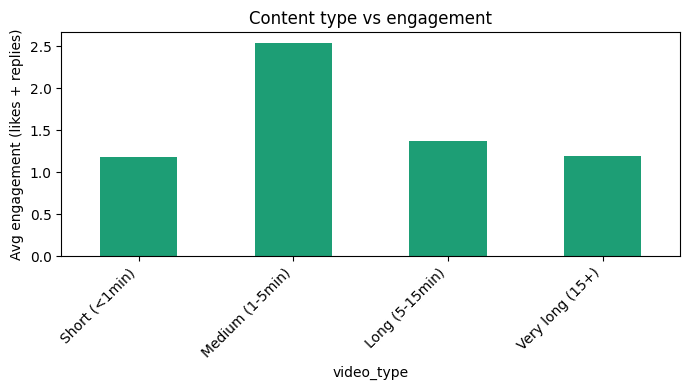

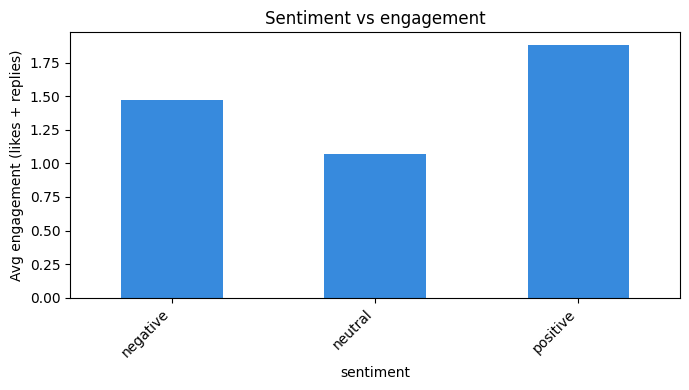

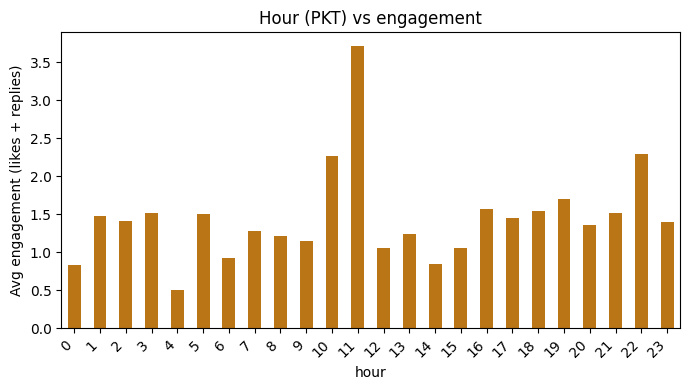

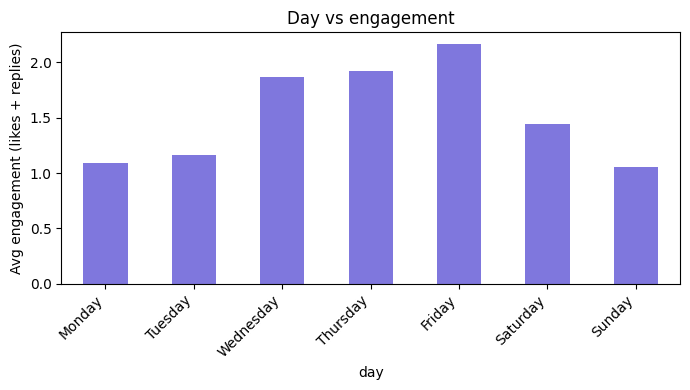

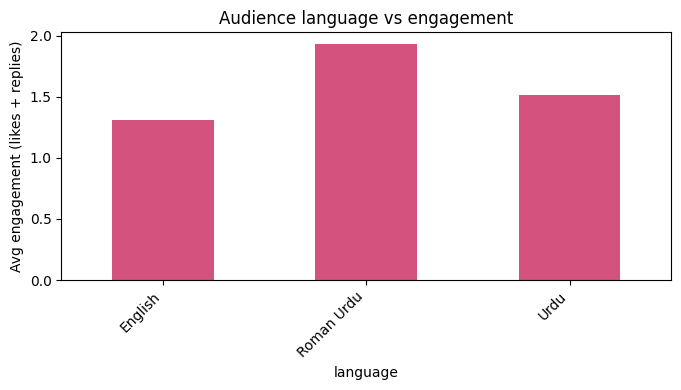

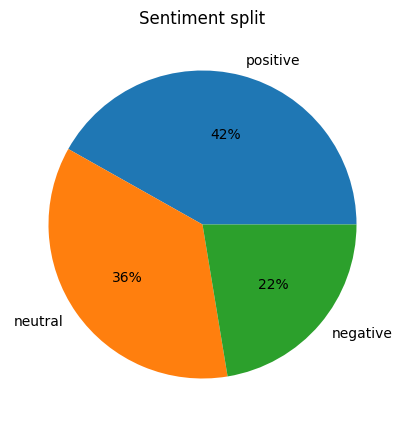

Top hashtags: [('#khaadi', 31), ('#khaadisale', 20), ('#khaadinewcollection', 16), ('#khaadipret', 13), ('#shopping', 12), ('#madawatv', 10), ('#pakistanifashion', 8), ('#shorts', 8), ('#summercollection', 8), ('#khaadipakistan', 8)]
channel
madawa tv              10
Misbah beauty tips      8
Khaadi                  6
Offers inside           4
hsk vlogs               4
Name: count, dtype: int64


In [5]:
import matplotlib.pyplot as plt
from collections import Counter

def bar(series, title, color="#1D9E75"):
    series.plot(kind="bar", figsize=(7,4), title=title, color=color)
    plt.ylabel("Avg engagement (likes + replies)")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

# Chart 1: Content type (video length)
df["video_type"] = pd.cut(df.duration, [0,60,300,900,100000],
                          labels=["Short (<1min)","Medium (1-5min)","Long (5-15min)","Very long (15+)"])
bar(df.groupby("video_type", observed=True).engagement.mean(), "Content type vs engagement")

# Chart 2: Sentiment vs engagement
bar(df.groupby("sentiment").engagement.mean(), "Sentiment vs engagement", "#378ADD")

# Chart 3: Hour of day (PKT)
bar(df.groupby("hour").engagement.mean(), "Hour (PKT) vs engagement", "#BA7517")

# Chart 4: Day of week
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
bar(df.groupby("day").engagement.mean().reindex(order), "Day vs engagement", "#7F77DD")

# Chart 5: Audience language
bar(df.groupby("language").engagement.mean(), "Audience language vs engagement", "#D4537E")

# Chart 6: Sentiment split
df.sentiment.value_counts().plot(kind="pie", autopct="%1.0f%%", figsize=(5,5),
                                 title="Sentiment split", ylabel="")
plt.show()

# Hashtags
tags = Counter(t.lower() for lst in df.drop_duplicates("video_id").hashtags for t in lst)
print("Top hashtags:", tags.most_common(10))

# Top channels
print(df.drop_duplicates("video_id").channel.value_counts().head(5))

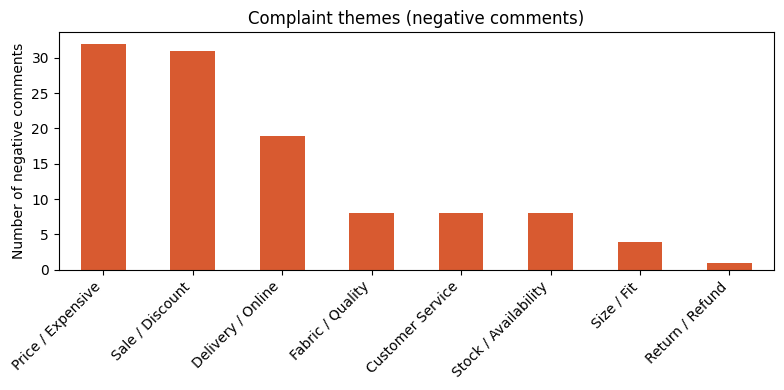

Price / Expensive       32
Sale / Discount         31
Delivery / Online       19
Fabric / Quality         8
Customer Service         8
Stock / Availability     8
Size / Fit               4
Return / Refund          1
dtype: int64

INSIGHTS: {'brand': 'Khaadi', 'best_content_type': 'Medium (1-5min)', 'best_hour': 11, 'best_day': 'Friday', 'best_language': 'Roman Urdu', 'top_sentiment_for_engagement': 'positive', 'top_hashtags': ['#khaadi', '#khaadisale', '#khaadinewcollection', '#khaadipret', '#shopping'], 'top_complaints': ['Price / Expensive', 'Sale / Discount', 'Delivery / Online']}

RECOMMENDATION FOR Khaadi
1. Content: Medium (1-5min) videos par sab se zyada engagement mili.
2. Timing: Friday ko, 11:00 PKT ke aas paas post karein.
3. Language: Roman Urdu mein caption aur replies likhein, audience isi mein zyada active hai.
4. Hashtags: #khaadi, #khaadisale, #khaadinewcollection, #khaadipret, #shopping.
5. Sab se pehle fix karein: Price / Expensive, Sale / Discount, Delivery / Online

In [6]:
neg = df[df.sentiment == "negative"]

# Khaadi (fashion brand) ke hisaab se complaint themes
THEMES = {
 "Fabric / Quality":      ["quality","fabric","cloth","kapra","kapray","stitching","fading","shrink","bekar","kharab","cheap"],
 "Price / Expensive":     ["price","prices","mehnga","expensive","costly","qeemat","rate","overpriced","afford"],
 "Size / Fit":            ["size","sizes","fit","fitting","chota","bara","loose","tight"],
 "Delivery / Online":     ["delivery","deliver","late","delay","courier","parcel","online","order","website","app"],
 "Stock / Availability":  ["stock","available","availability","sold","out","restock"],
 "Sale / Discount":       ["sale","discount","offer","offers","off","voucher"],
 "Customer Service":      ["customer","service","support","helpline","complaint","response","reply","staff","rude"],
 "Return / Refund":       ["refund","return","exchange","replace","wapis","paisa","paise"],
}

def has_theme(text, words):
    toks = set(text.split())
    return any(w in toks for w in words)

theme_count = {k: int(neg.clean_text.apply(lambda t: has_theme(t, kws)).sum())
               for k, kws in THEMES.items()}
theme_series = pd.Series(theme_count).sort_values(ascending=False)

theme_series.plot(kind="bar", color="#D85A30", figsize=(8,4),
                  title="Complaint themes (negative comments)")
plt.ylabel("Number of negative comments")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
print(theme_series)

# Insights
best = lambda col: df.groupby(col, observed=True).engagement.mean().idxmax()
insights = {
  "brand": BRAND,
  "best_content_type": str(best("video_type")),
  "best_hour": int(best("hour")),
  "best_day": best("day"),
  "best_language": best("language"),
  "top_sentiment_for_engagement": best("sentiment"),
  "top_hashtags": [t for t, _ in tags.most_common(5)],
  "top_complaints": theme_series.head(3).index.tolist(),
}
print("\nINSIGHTS:", insights)

print(f"""
RECOMMENDATION FOR {BRAND}
1. Content: {insights['best_content_type']} videos par sab se zyada engagement mili.
2. Timing: {insights['best_day']} ko, {insights['best_hour']}:00 PKT ke aas paas post karein.
3. Language: {insights['best_language']} mein caption aur replies likhein, audience isi mein zyada active hai.
4. Hashtags: {', '.join(insights['top_hashtags']) if insights['top_hashtags'] else 'brand-specific hashtags banayein'}.
5. Sab se pehle fix karein: {', '.join(insights['top_complaints'])}, kyunke negative comments ka bara hissa inhi ke baare mein hai.
6. Sentiment: {insights['top_sentiment_for_engagement']} comments par sab se zyada engagement aati hai, in comments ko jaldi reply karein.
""")

# README ke liye saare numbers
vids = df.drop_duplicates("video_id")
print("=" * 40)
print("README NUMBERS")
print("Videos used:", len(vids))
print("Comments (cleaned):", len(df))
print("Official Khaadi channel videos:", int((vids.channel.str.lower() == "khaadi").sum()))
print("\nLanguage:\n", df.language.value_counts().to_string())
print("\nSentiment counts:\n", df.sentiment.value_counts().to_string())
print("\nSentiment %:\n", (df.sentiment.value_counts(normalize=True) * 100).round(0).to_string())

In [7]:
!pip install -q pyspark
from pyspark.sql import SparkSession, functions as F

spark = SparkSession.builder.appName("KhaadiContentDetective").getOrCreate()
sdf = spark.read.csv("final_data.csv", header=True, inferSchema=True,
                     multiLine=True, escape='"')

print("Total rows in Spark:", sdf.count())

print("--- Sentiment vs engagement ---")
sdf.groupBy("sentiment").agg(F.count("*").alias("comments"),
                             F.round(F.avg("engagement"), 2).alias("avg_engagement")).show()

print("--- Language segments ---")
sdf.groupBy("language").agg(F.count("*").alias("comments"),
                            F.round(F.avg("engagement"), 2).alias("avg_engagement")).show()

print("--- Best hours (PKT) ---")
sdf.groupBy("hour").agg(F.round(F.avg("engagement"), 2).alias("avg_engagement")) \
   .orderBy(F.desc("avg_engagement")).show(5)

print("--- Best days ---")
sdf.groupBy("day").agg(F.round(F.avg("engagement"), 2).alias("avg_engagement")) \
   .orderBy(F.desc("avg_engagement")).show()

Total rows in Spark: 2005
--- Sentiment vs engagement ---
+---------+--------+--------------+
|sentiment|comments|avg_engagement|
+---------+--------+--------------+
| positive|     839|          1.88|
|  neutral|     717|          1.07|
| negative|     449|          1.47|
+---------+--------+--------------+

--- Language segments ---
+----------+--------+--------------+
|  language|comments|avg_engagement|
+----------+--------+--------------+
|Roman Urdu|     597|          1.93|
|      Urdu|      70|          1.51|
|   English|    1338|          1.31|
+----------+--------+--------------+

--- Best hours (PKT) ---
+----+--------------+
|hour|avg_engagement|
+----+--------------+
|  11|          3.71|
|  22|          2.29|
|  10|          2.27|
|  19|          1.71|
|  16|          1.57|
+----+--------------+
only showing top 5 rows
--- Best days ---
+---------+--------------+
|      day|avg_engagement|
+---------+--------------+
|   Friday|          2.16|
| Thursday|          1.92|
|We